In [3]:
 # pip install-learn         
# conda install scikit-learn

In [1]:
import sklearn
print(sklearn.__version__)

1.7.2


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# 1.  PROBLEM DEFINITION

The Titanic dataset contains information about passengers who were aboard the
Titanic. Our goal is to build a machine learning model that can predict whether a
passenger (would):
Survived the Titanic ( 1 )
Did not survive the Titanic ( 0 )
This is a classification problem because the output belongs to one of two
categories.

# 2. DATA COLLECTION AND PREPARATION

In [3]:
#import file
titanic_data = pd.read_csv('data/titanic.csv')
titanic_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,PaCh,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [5]:
# You can also get this data from seaborn
#import seaborn as sns
#df = sns.load_dataset("titanic")

In [4]:
# We've done viz for this dataset, so I'll skip it.
titanic_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  887 non-null    int64  
 1   Pclass    887 non-null    int64  
 2   Name      887 non-null    object 
 3   Sex       887 non-null    object 
 4   Age       887 non-null    float64
 5   SibSp     887 non-null    int64  
 6   PaCh      887 non-null    int64  
 7   Fare      887 non-null    float64
dtypes: float64(2), int64(4), object(2)
memory usage: 55.6+ KB


# Understanding the Dataset


Some important columns include:
survived : whether the passenger survived
pclass : passenger class
sex : passenger's sex
age : passenger's age
sibsp : number of siblings/spouses aboard
parch : number of parents/children aboard
fare : ticket fare
embarked : port where the passenger boarded
Our target variable is:
survived
The other useful columns will be used as features.

# Let's do some exploration

In [9]:
titanic_data.describe()

,Survived,Pclass,Age,SibSp,PaCh,Fare
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920


In [10]:
# counts the total number of people that survived and people that died
titanic_data['Survived'].value_counts()

Survived
0    545
1    342
Name: count, dtype: int64

In [24]:
# Check if there are any column with missing values

titanic_data.isnull().sum()

Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
PaCh        0
Fare        0
dtype: int64

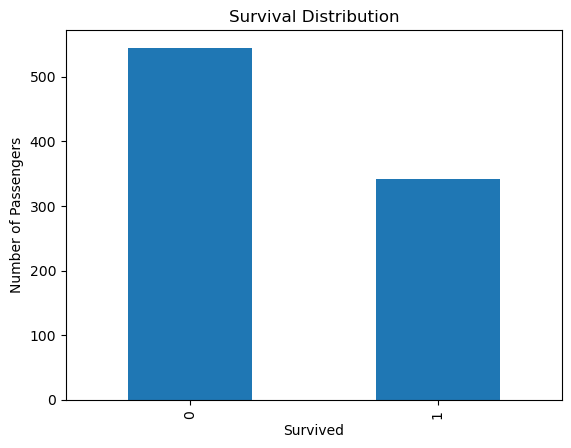

In [5]:
# Plot your data to see if there is biasness or not or other things

titanic_data["Survived"].value_counts().plot(kind="bar")
plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")
plt.show()

### let's select the important features
##### We'll use:
pclass
sex
age
sibsp
parch
fare

# SELECTING THE IMPORTANT FEATURES as (X) and (y) 

In [6]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'PaCh', 'Fare']   # features/attributes/independent variable/

target = 'Survived'                # target variable/dependent variable

X = titanic_data[features].copy()        # select the features we will be needing (X)
y = titanic_data[target].copy()           # SELECT OUR TARGET variable and make it (y)

In [5]:
X.head()

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,male,22.0,1,0,7.2500
1,1,female,38.0,1,0,71.2833
2,3,female,26.0,0,0,7.9250
3,1,female,35.0,1,0,53.1000
4,3,male,35.0,0,0,8.0500


In [27]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

# Clean the Data
### Handle MISSING VALUES
### WRONG FORMAT    ( The Sex that is male and female, turn it to 1 for female and 0 for male)


# Converting Categorical data into numbers (ENCODING)

In [7]:
X['Sex'] = X['Sex'].apply(lambda x: 1 if x == 'female' else 0)

# X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})
X.head()

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,0,22.0,1,0,7.2500
1,1,1,38.0,1,0,71.2833
2,3,1,26.0,0,0,7.9250
3,1,1,35.0,1,0,53.1000
4,3,0,35.0,0,0,8.0500


In [ ]:
# THIS CAN BE USED FOR ENCODING TOO ESPecially if you have more than one column. just seperate with a comma

#X= pd.get_dummies(X,
#columns=["Sex"],
#drop_first=True
#)

# SPLIT THE DATA

Train/Test Split

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#test_size=0.2  means take 20% for testing and 80% for training
#random_state=42  means it shows thesame random data each time you call it with 42. you can use any number
#statisfy=y means that focusing on target variable(y) to get same proportion of splittig the data to avoid biasness 

In [10]:
print('Training data:', X_train.shape)
print('Training data:', X_test.shape)

Training data: (709, 6)
Training data: (178, 6)


# Feature Scaling
#### (some models are not affected, but for logistic regression we have to scale)
## Scaler is turning numerical value of different range eg age 10, 100, fare 1000 

In [11]:
scaler = StandardScaler()                 # creating an instance of StandaredScaler

X_train_scaled = scaler.fit_transform(X_train)        # fit_transform() on the training data.
X_test_scaled = scaler.transform(X_test)              # transform() on the testing data.

# The scaler should learn the scaling information from the training data only.
# The test data should remain unseen until evaluation.

# 3. Choosing Our Models (Model Selection)

We will compare three classification algorithms:
### 1. Logistic Regression
A simple and popular classification algorithm.
### 2. Decision Tree
Makes decisions by asking a series of questions about the data.
### 3. Random Forest
Combines multiple decision trees to make predictions.
We will train all three models and compare their performance.

# LET'S START TRAINING(LOGISTIC REGRESSION)

In [12]:

logistic_model = LogisticRegression(max_iter=10000)   # max_iteration means, go over my data 1000 times 
logistic_model.fit(X_train_scaled, y_train)          # fit means train. fit(questions, question)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [13]:
logistic_predictions = logistic_model.predict(X_test_scaled)          # pass in the question 
logistic_accuracy = accuracy_score(                                   # compare the answer 
y_test,
logistic_predictions
)
print("Logistic Regression Accuracy:", logistic_accuracy)


# the result shows that we have 76% accuracy

Logistic Regression Accuracy: 0.7696629213483146


In [14]:
print(classification_report(y_test, logistic_predictions))

              precision    recall  f1-score   support

           0       0.80      0.83      0.81       109
           1       0.71      0.68      0.70        69

    accuracy                           0.77       178
   macro avg       0.76      0.75      0.76       178
weighted avg       0.77      0.77      0.77       178



# TRAIN with DecisionTreeClassifier

In [16]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [17]:
tree_model = DecisionTreeClassifier( max_depth=3,
random_state=42
)
tree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [18]:
tree_predictions = tree_model.predict(X_test)
tree_accuracy = accuracy_score(
y_test,
tree_predictions
)
print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.8033707865168539


In [20]:
print(classification_report(y_test, tree_predictions))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       109
           1       0.79      0.67      0.72        69

    accuracy                           0.80       178
   macro avg       0.80      0.78      0.79       178
weighted avg       0.80      0.80      0.80       178



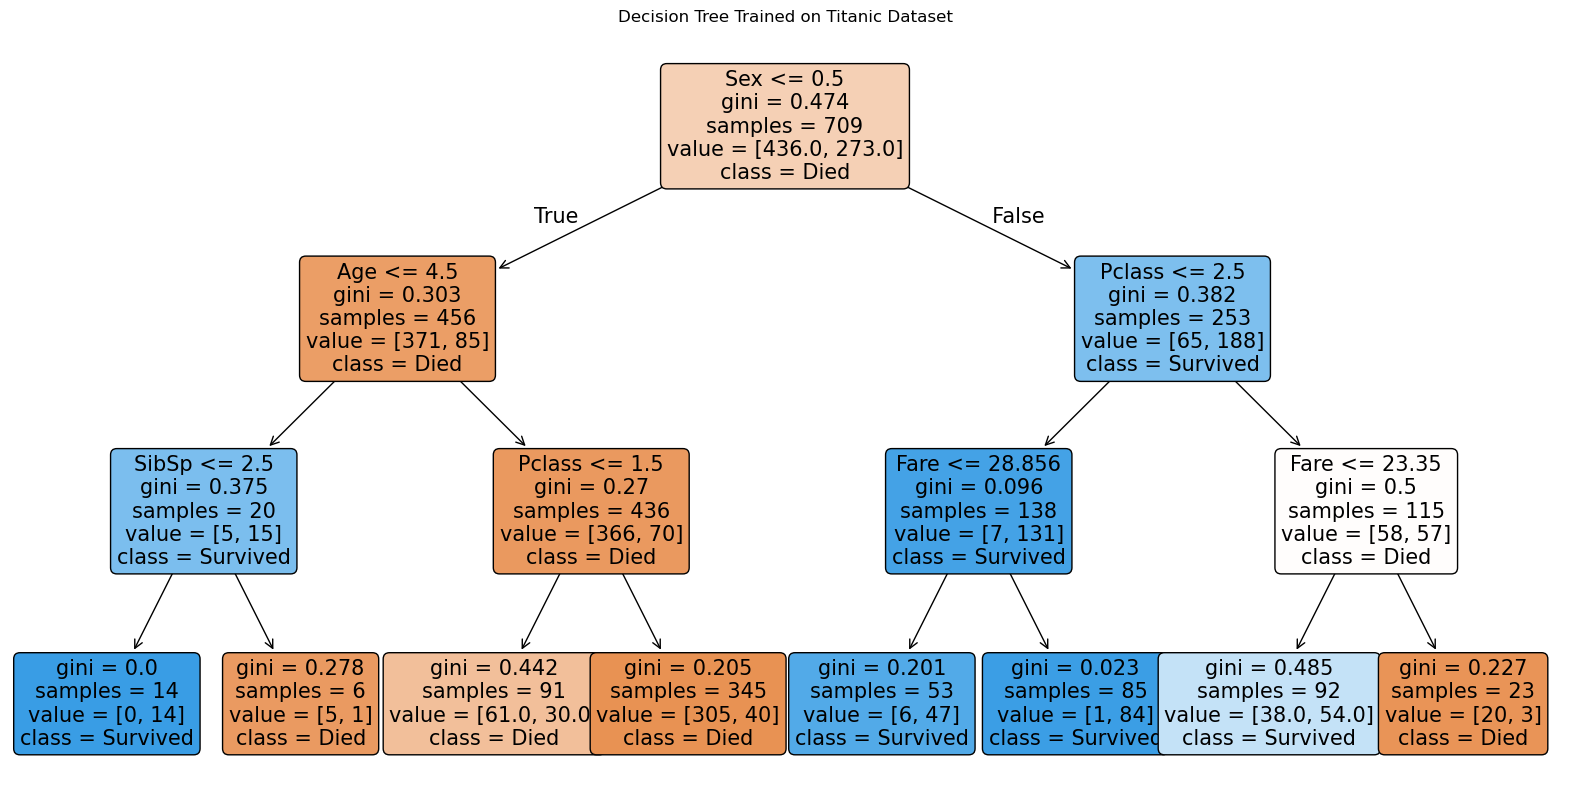

In [21]:
plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=features,
    class_names= ["Died", "Survived"],
    filled=True,
    rounded=True,
    fontsize=15,

)

plt.title("Decision Tree Trained on Titanic Dataset")
plt.show()

# TRAIN with RandomForestClassifier

In [22]:
# TRAIN with Random Forest

forest_model = RandomForestClassifier(
    random_state = 42,
    n_estimators=100,
    max_depth=3
)

forest_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [23]:
forest_predictions = forest_model.predict(X_test)
forest_accuracy = accuracy_score(
y_test,
forest_predictions
)
print("Random Forest Accuracy:", forest_accuracy)

Random Forest Accuracy: 0.8089887640449438


In [24]:
print(classification_report(y_test, forest_predictions))

              precision    recall  f1-score   support

           0       0.82      0.89      0.85       109
           1       0.80      0.68      0.73        69

    accuracy                           0.81       178
   macro avg       0.81      0.79      0.79       178
weighted avg       0.81      0.81      0.81       178



# Let's compare out Models

In [25]:
# Let's compare out Models

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy * 100,
        tree_accuracy * 100,
        forest_accuracy * 100
    ]
})

results.round(2)            # remove it from decimal to 10s

,Model,Accuracy
0,Logistic Regression,76.97
1,Decision Tree,80.34
2,Random Forest,80.90


In [73]:
results.sort_values(by='Accuracy', ascending=False).round(2)        

,Model,Accuracy
2,Random Forest,82.54
0,Logistic Regression,81.69
1,Decision Tree,79.72


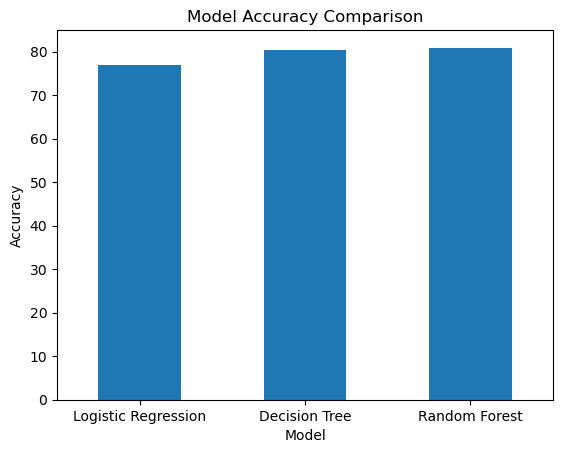

In [26]:
# plot it
results.plot(
x="Model",
y="Accuracy",
kind="bar",
legend=False
)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.show()

### What did we learn?
### We trained three different models on the same problem.
### The models may produce different results because they learn patterns from the data differently.
### At this stage, we have a baseline performance for each model.
### Next, we will try to improve the models using hyperparameter tuning.

In [28]:
forest_model_2 = RandomForestClassifier(
    random_state = 42,
    #n_estimators=100,
    #max_depth=8,
    #min_samples_split=2
)

forest_model_2.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [25]:
forest_predictions_2 = forest_model.predict(X_test)
forest_accuracy_2 = accuracy_score(
y_test,
forest_predictions_2
)
print("Random Forest Accuracy:", forest_accuracy_2)

Random Forest Accuracy: 0.8253521126760563


# Tuning & Optimization (hyperparameters)

In [29]:
# Tune the Decision Tree
tree_params = {
"max_depth": [2, 3, 4, 5, 6, 8, 10],
}
tree_grid = GridSearchCV(
DecisionTreeClassifier(random_state=42),
tree_params,
cv=5,
scoring="accuracy"
)

In [30]:
tree_grid.fit(X_train, y_train)

,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'max_depth': [2, 3, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [36]:
# USE GRIDSEARCHCV Tune the Random Forest to get the best paramters


forest_params = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 7, 10]
}
forest_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    forest_params,
    cv=5,
    scoring="accuracy"
)
forest_grid.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,50


In [32]:
print("Best Parameters:")
print(tree_grid.best_params_)
print("Best Cross-Validation Accuracy:")
print(tree_grid.best_score_)

Best Parameters:
{'max_depth': 4}
Best Cross-Validation Accuracy:
0.818060133852762


In [34]:
# Evaluate the Tuned Decision Tree
best_tree = tree_grid.best_estimator_
tuned_tree_predictions = best_tree.predict(X_test)
tuned_tree_accuracy = accuracy_score(
    y_test,
    tuned_tree_predictions
)
print("Tuned Decision Tree Accuracy:", tuned_tree_accuracy)

Tuned Decision Tree Accuracy: 0.8033707865168539


In [35]:
# Tune the Random Forest
forest_params = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 7, 10]
}
forest_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    forest_params,
    cv=5,
    scoring="accuracy"
)
forest_grid.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,50


In [36]:
print("Best Parameters:")
print(forest_grid.best_params_)
print("\nBest Cross-Validation Accuracy:")
print(forest_grid.best_score_)

Best Parameters:
{'max_depth': 7, 'n_estimators': 50}

Best Cross-Validation Accuracy:
0.8392168614524025


In [37]:
best_forest = forest_grid.best_estimator_
tuned_forest_predictions = best_forest.predict(X_test)
tuned_forest_accuracy = accuracy_score(
    y_test,
    tuned_forest_predictions
)
print(
    "Tuned Random Forest Accuracy:",
    tuned_forest_accuracy
)

Tuned Random Forest Accuracy: 0.797752808988764


In [38]:
print(classification_report(y_test, tuned_forest_predictions))

              precision    recall  f1-score   support

           0       0.81      0.88      0.84       109
           1       0.78      0.67      0.72        69

    accuracy                           0.80       178
   macro avg       0.79      0.77      0.78       178
weighted avg       0.80      0.80      0.79       178



In [41]:
# Compare Before and After Tuning
final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree - Before Tuning",
        "Decision Tree - After Tuning",
        "Random Forest - Before Tuning",
        "Random Forest - After Tuning"
    ],

    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        tuned_tree_accuracy,
        forest_accuracy,
        tuned_forest_accuracy
    ]
})
final_results

,Model,Accuracy
0,Logistic Regression,0.769663
1,Decision Tree - Before Tuning,0.803371
2,Decision Tree - After Tuning,0.803371
3,Random Forest - Before Tuning,0.808989
4,Random Forest - After Tuning,0.797753


# PREDICTION FUNCTION

In [44]:
 def predict_survival(name, Pclass, Sex, Age, SibSp, PaCh, Fare):
    """""
    Predict survival using our model
    """""
    input_data = pd.DataFrame({
        'Pclass': [Pclass],
        'Sex': [Sex],
        'Age': [Age],
        'SibSp': [SibSp],
        'PaCh': [PaCh],
        'Fare': [Fare]
    })
    prediction = best_forest.predict(input_data)[0]
    probabilities = best_forest.predict_proba(input_data)[0]           # to explain
     
    if prediction == 0:
        result = f'wooo 😭 {name.title()}, you Died 🥲'
    else:
        result = f'Cheers 🥂 {name.title()}, you Survived 😁'

    return result, probabilities

In [45]:
print(predict_survival('Tomi', Pclass=3, Sex=1, Age=25.0, SibSp=0, PaCh=0, Fare=100))

('Cheers 🥂 Tomi, you Survived 😁', array([0.37671003, 0.62328997]))


In [47]:
input_data = pd.DataFrame({
        'Pclass': [1],
        'Sex': [1],
        'Age': [23],
        'SibSp': [1],
        'PaCh': [1],
        'Fare': [1]
    })
input_data

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,1,1,23,1,1,1


# ASSIGNMENT 
### (Train an SVM MODEL with titanic using GridSearchCV)

In [50]:
svm_model = SVC(cache_size=300, max_iter = 1000, probability = True,
random_state=42
)
svm_model.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,300
,class_weight,None
,verbose,False


In [51]:
svc_predictions = svm_model.predict(X_test)
svc_accuracy = accuracy_score(
y_test,
svc_predictions
)
print("Support Vector Machine Accuracy:", svc_accuracy)

Support Vector Machine Accuracy: 0.6404494382022472


In [57]:
print(classification_report(y_test, svc_predictions))

              precision    recall  f1-score   support

           0       0.65      0.91      0.76       109
           1       0.60      0.22      0.32        69

    accuracy                           0.64       178
   macro avg       0.62      0.56      0.54       178
weighted avg       0.63      0.64      0.59       178



In [58]:
from sklearn.model_selection import GridSearchCV

In [59]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(random_state=42))
])

In [61]:
svm_params = {
    "svc__max_iter": [1000, 2000, 4000],
    "svc__C": [0.1, 1, 10, 100]
}

svm_grid = GridSearchCV(
    pipeline,
    svm_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Best Parameters:")
print(svm_grid.best_params_)
print("\nBest CV Accuracy:")
print(svm_grid.best_score_)

Best Parameters:
{'svc__C': 10, 'svc__max_iter': 1000}

Best CV Accuracy:
0.8293377284986514


C:\Users\USER-PC\Videos\WEBFALA\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


# THE END